# Preprocessing and Feature Extraction

### Authors - Shivendra Raghav (1001123853), Amirhosein Morteza (1002187551)
### CSE 5388-002

#### This files preprocesses the data and does feature extraction.

### Import the required libraries

In [25]:
import nltk
import pickle
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import gensim.downloader as api
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler
from sklearn.model_selection import train_test_split
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

In [26]:
nltk.download("punkt")

glove_model = api.load("glove-wiki-gigaword-300")

[nltk_data] Downloading package punkt to
[nltk_data]     /Users/shivendraraghav/nltk_data...
[nltk_data]   Package punkt is already up-to-date!


### Load the dataset

In [27]:
df = pd.read_csv("../synthetic_dataset/sentence_classified_data.csv")

df.head()

,filename,sentence_with_placeholder,sentence,sensitive,ner_metadata
0,email_enron_jones-t_sent_2182_prompt_1_not_pro...,Message-ID: <10746365.1075847203014.JavaMail.e...,Message-ID: <10746365.1075847203014.JavaMail.e...,0,[]
1,email_enron_jones-t_sent_2182_prompt_1_not_pro...,"To: david.minns@enron.com, jane.mcbride@enron....","To: david.minns@enron.com, jane.mcbride@enron....",0,[]
2,email_enron_jones-t_sent_2182_prompt_1_not_pro...,I hope this email finds you well.,I hope this email finds you well.,0,[]
3,email_enron_jones-t_sent_2182_prompt_1_not_pro...,Please find the access details for the ISDA Ma...,Please find the access details for the ISDA Ma...,1,"[('H-oex9tb4EOetNtymPQ0W7UsaSVqtHivmp1XzpgP', ..."
4,email_enron_jones-t_sent_2182_prompt_1_not_pro...,You should now have edit access to the referen...,You should now have edit access to the referen...,0,[]


In [28]:
# Check for missing values
df.isnull().sum()

filename                     0
sentence_with_placeholder    0
sentence                     0
sensitive                    0
ner_metadata                 0
dtype: int64

### Data Cleaning and Preprocessing

In [29]:
# Tokenize sentences
df["tokens"] = df["sentence"].apply(nltk.word_tokenize)

# Remove sentences with less than 2 words
df = df[df["tokens"].apply(len) > 2]

# Remove sentences with more than 50 words
df = df[df["tokens"].apply(len) < 50]

# Join tokens back into sentences
df["processed_sentence"] = df["tokens"].apply(lambda x: " ".join(x))

# Drop duplicates and empty sentences
df.drop_duplicates(subset="processed_sentence", inplace=True)
df.dropna(subset=["processed_sentence"], inplace=True)

df.head()

,filename,sentence_with_placeholder,sentence,sensitive,ner_metadata,tokens,processed_sentence
0,email_enron_jones-t_sent_2182_prompt_1_not_pro...,Message-ID: <10746365.1075847203014.JavaMail.e...,Message-ID: <10746365.1075847203014.JavaMail.e...,0,[],"[Message-ID, :, <, 10746365.1075847203014.Java...",Message-ID : < 10746365.1075847203014.JavaMail...
2,email_enron_jones-t_sent_2182_prompt_1_not_pro...,I hope this email finds you well.,I hope this email finds you well.,0,[],"[I, hope, this, email, finds, you, well, .]",I hope this email finds you well .
3,email_enron_jones-t_sent_2182_prompt_1_not_pro...,Please find the access details for the ISDA Ma...,Please find the access details for the ISDA Ma...,1,"[('H-oex9tb4EOetNtymPQ0W7UsaSVqtHivmp1XzpgP', ...","[Please, find, the, access, details, for, the,...",Please find the access details for the ISDA Ma...
4,email_enron_jones-t_sent_2182_prompt_1_not_pro...,You should now have edit access to the referen...,You should now have edit access to the referen...,0,[],"[You, should, now, have, edit, access, to, the...",You should now have edit access to the referen...
5,email_enron_jones-t_sent_2182_prompt_1_not_pro...,Non-legal or credit employees can only get vie...,Non-legal or credit employees can only get vie...,0,[],"[Non-legal, or, credit, employees, can, only, ...",Non-legal or credit employees can only get vie...


### Data Exploration

/var/folders/rz/4djzw0r155g8_kdwpx3gm7y40000gn/T/ipykernel_72216/2708613916.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x="sensitive", data=df, palette=["#175676", "#d62839"])


Text(0.5, 0, 'Sensitive')

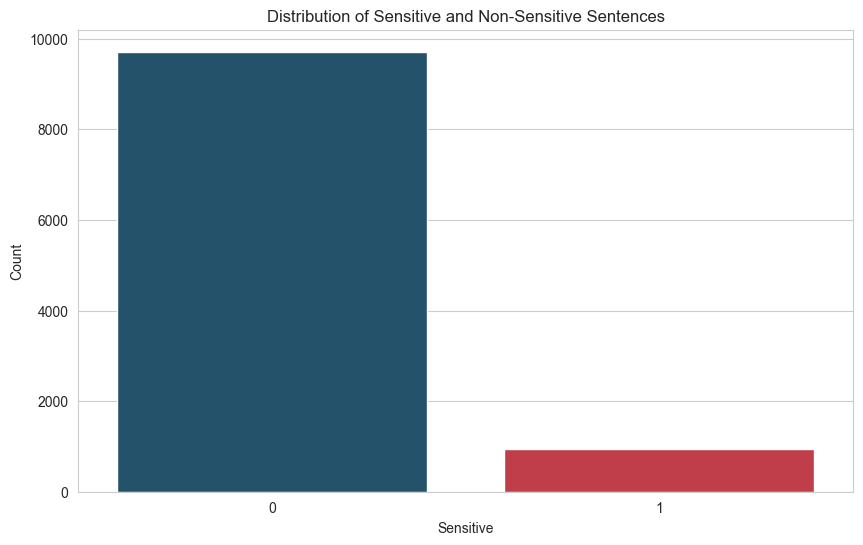

In [30]:
# Distribution of Sensitive and Non-Sensitive Sentences
plt.figure(figsize=(10, 6))
sns.set_style("whitegrid")
sns.countplot(x="sensitive", data=df, palette=["#175676", "#d62839"])
plt.title("Distribution of Sensitive and Non-Sensitive Sentences")
plt.ylabel("Count")
plt.xlabel("Sensitive")

### GloVe Embeddings and Balancing the dataset

In [31]:
text_tokenizer = Tokenizer()
text_tokenizer.fit_on_texts(df["sentence"])

# Save the tokenizer
text_tokenizer_path = "output/text_tokenizer.pickle"
with open(text_tokenizer_path, "wb") as handle:
    pickle.dump(text_tokenizer, handle, protocol=pickle.HIGHEST_PROTOCOL)

In [32]:
# Word Index
word_index = text_tokenizer.word_index

# Create a weight matrix for words in training docs
def create_embedding_matrix(word_index, embedding_model):
    embedding_matrix = np.zeros((len(word_index) + 1, embedding_model.vector_size))
    for word, i in word_index.items():
        if word in embedding_model.key_to_index:
            embedding_matrix[i] = embedding_model[word]
    return embedding_matrix

embedding_matrix = create_embedding_matrix(word_index, glove_model)

# Save the embedding matrix
glove_embeddings_path = "output/glove_embeddings.npz"
np.savez_compressed(glove_embeddings_path, embedding_matrix=embedding_matrix)


In [33]:
# Balance the dataset
# smote = SMOTE(random_state=42)
undersampler = RandomUnderSampler(random_state=42)

X = text_tokenizer.texts_to_sequences(df["sentence"])

max_length = 100
X = pad_sequences(X, maxlen=max_length, padding="post")

# X_resampled, y_resampled = smote.fit_resample(X, df["sensitive"])
X_resampled, y_resampled = undersampler.fit_resample(X, df["sensitive"])

# Save the resampled data
df_resampled = pd.DataFrame(columns=["processed_sentence", "sensitive"])
df_resampled["sensitive"] = y_resampled
df_resampled["processed_sentence"] = text_tokenizer.sequences_to_texts(X_resampled)

/var/folders/rz/4djzw0r155g8_kdwpx3gm7y40000gn/T/ipykernel_72216/3206030609.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x="sensitive", data=df_resampled, palette=["#175676", "#d62839"])


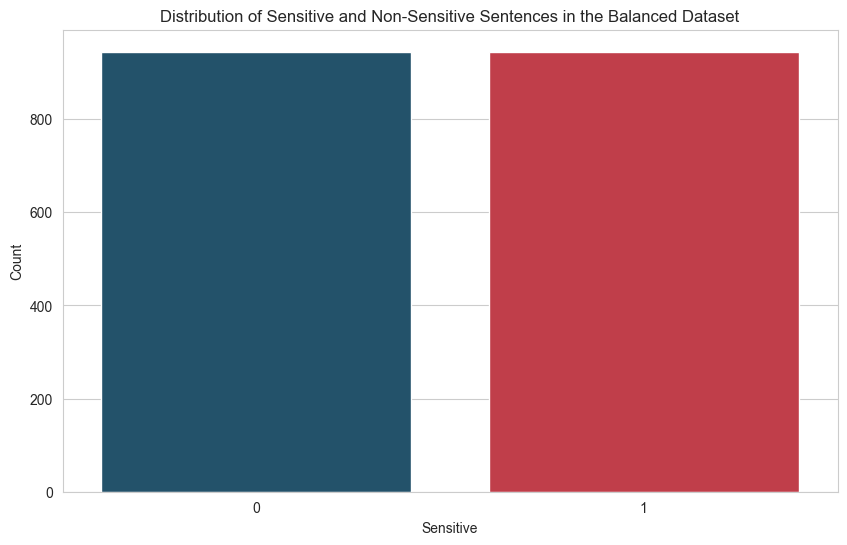

In [34]:
# Distribution of Sensitive and Non-Sensitive Sentences in the Balanced Dataset
plt.figure(figsize=(10, 6))
sns.set_style("whitegrid")
sns.countplot(x="sensitive", data=df_resampled, palette=["#175676", "#d62839"])
plt.title("Distribution of Sensitive and Non-Sensitive Sentences in the Balanced Dataset")
plt.ylabel("Count")
plt.xlabel("Sensitive")
plt.show()

### Save the data

In [35]:
# Save the resampled data
df_resampled["processed_sentence"] = df_resampled["processed_sentence"].apply(lambda x: x.strip())
df_resampled["sensitive"] = df_resampled["sensitive"].astype(int)

df_resampled.to_csv("../synthetic_dataset/sentence_classified_data_resampled.csv", index=False)

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X_resampled, y_resampled, test_size=0.2, random_state=42)

# Save the training and testing data
np.savez_compressed("output/train_data.npz", X_train=X_train, y_train=y_train)
np.savez_compressed("output/test_data.npz", X_test=X_test, y_test=y_test)